# Solving the n-Queens Problem using Local Search

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [1]:
# Run this notebook from its folder (Jupyter's current working directory).
# No machine-specific path is required. If using Colab, upload the notebook and
# run the cells in order; keep all project files together when needed.


## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [2]:
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


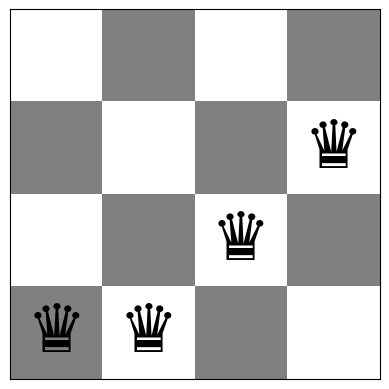

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [3]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


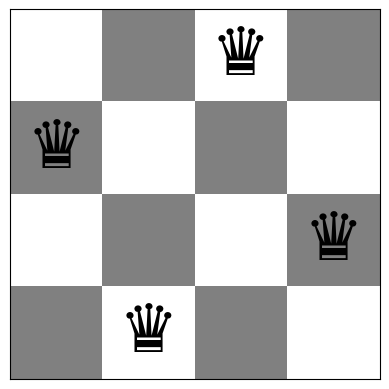

In [4]:
board = [1,3,0,2]
show_board(board)

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

{'conflicts': 0, 'steps': 5, 'evaluations': 281}
Board with 0 conflicts.


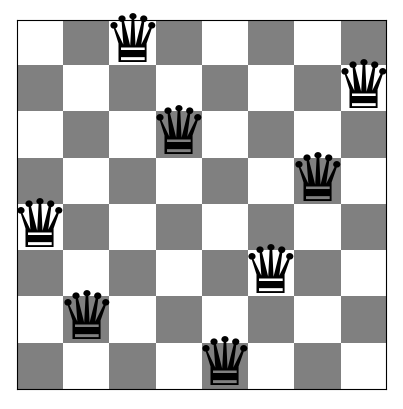

In [5]:
def steepest_hill_climbing(board, max_steps=10_000):
    """Evaluate every legal single-queen move and take the best strict improvement."""
    board = np.array(board, dtype=int).copy()
    history = [conflicts(board)]
    evaluations = 1
    n = len(board)
    for _ in range(max_steps):
        current = conflicts(board)
        best_board, best_value = board, current
        for col in range(n):
            old_row = board[col]
            for row in range(n):
                if row == old_row:
                    continue
                neighbor = board.copy(); neighbor[col] = row
                value = conflicts(neighbor); evaluations += 1
                if value < best_value:
                    best_board, best_value = neighbor, value
        if best_value >= current:
            break
        board = best_board.copy(); history.append(best_value)
        if best_value == 0: break
    return {"board": board, "conflicts": conflicts(board), "steps": len(history)-1,
            "evaluations": evaluations, "history": history}

result = steepest_hill_climbing(random_board(8))
print({k:v for k,v in result.items() if k not in ('board','history')})
show_board(result['board'])


## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

In [6]:
def stochastic_hill_climbing_all(board, max_steps=10_000):
    """Evaluate all neighbors; randomly select among strict improving moves."""
    board = np.array(board, dtype=int).copy(); n = len(board)
    history = [conflicts(board)]; evaluations = 1
    for _ in range(max_steps):
        current = conflicts(board)
        improving = []
        for col in range(n):
            for row in range(n):
                if row == board[col]: continue
                neighbor = board.copy(); neighbor[col] = row
                value = conflicts(neighbor); evaluations += 1
                if value < current: improving.append((neighbor, value))
        if not improving: break
        best_value = min(v for _,v in improving)
        # Stochastic choice among all improving moves, not necessarily only the best.
        candidates = [(b,v) for b,v in improving if v < current]
        board, value = candidates[np.random.randint(len(candidates))]
        history.append(value)
        if value == 0: break
    return {"board": board, "conflicts": conflicts(board), "steps": len(history)-1,
            "evaluations": evaluations, "history": history}

result = stochastic_hill_climbing_all(random_board(8))
print({k:v for k,v in result.items() if k not in ('board','history')})


{'conflicts': 1, 'steps': 7, 'evaluations': 449}


__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

In [7]:
def stochastic_hill_climbing(board, max_trials=None, max_steps=10_000):
    """Sample random single-queen moves; accept strict improvements only."""
    board = np.array(board, dtype=int).copy(); n = len(board)
    if max_trials is None: max_trials = max(50, 10*n*n)
    history = [conflicts(board)]; evaluations = 1; trials_without_improvement = 0
    for _ in range(max_steps):
        if conflicts(board) == 0: break
        col = np.random.randint(n); row = np.random.randint(n-1)
        if row >= board[col]: row += 1
        neighbor = board.copy(); neighbor[col] = row
        value = conflicts(neighbor); evaluations += 1
        if value < conflicts(board):
            board = neighbor; history.append(value); trials_without_improvement = 0
        else:
            trials_without_improvement += 1
        if trials_without_improvement >= max_trials: break
    return {"board": board, "conflicts": conflicts(board), "steps": len(history)-1,
            "evaluations": evaluations, "history": history}

result = stochastic_hill_climbing(random_board(8))
print({k:v for k,v in result.items() if k not in ('board','history')})


{'conflicts': 2, 'steps': 4, 'evaluations': 658}


## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

In [8]:
def random_restart(algorithm, n, restarts=100, seed=None, **kwargs):
    """Run a hill-climbing variant from multiple independent random initial boards."""
    if seed is not None: np.random.seed(seed)
    best = None; runs = []
    for restart in range(1, restarts+1):
        result = algorithm(random_board(n), **kwargs)
        runs.append(result)
        if best is None or result['conflicts'] < best['conflicts']:
            best = result.copy(); best['restart_found'] = restart
        if best['conflicts'] == 0: break
    best['restarts_used'] = len(runs)
    best['runs'] = runs
    return best

for name, alg in [('Steepest', steepest_hill_climbing),
                  ('Stochastic-all', stochastic_hill_climbing_all),
                  ('Stochastic-random', stochastic_hill_climbing)]:
    rr = random_restart(alg, 8, restarts=100)
    print(name, 'best conflicts=', rr['conflicts'], 'restarts=', rr['restarts_used'])


Steepest best conflicts= 0 restarts= 2
Stochastic-all best conflicts= 0 restarts= 1
Stochastic-random best conflicts= 0 restarts= 2


### Random Restart - benchmark lặp lại nhiều lần

Để ước tính tỉ lệ tìm được lời giải không xung đột (như đề yêu cầu), ta lặp lại `random_restart` 100 lần độc lập cho mỗi biến thể Hill Climbing, trên cả n=4 và n=8, mỗi lần cho phép tối đa 100 lần khởi động.

In [9]:
# Random Restart: lap lai 100 lan doc lap de uoc tinh ti le thanh cong va so lan khoi dong trung binh
rr_rows = []
for n in (4, 8):
    for name, alg in [('Steepest HC', steepest_hill_climbing),
                       ('Stochastic all moves', stochastic_hill_climbing_all),
                       ('Efficient stochastic', stochastic_hill_climbing)]:
        confl = []; restarts_used = []; durations = []
        for rep in range(100):
            start = time.perf_counter()
            rr = random_restart(alg, n, restarts=100)
            durations.append((time.perf_counter()-start)*1000)
            confl.append(rr['conflicts']); restarts_used.append(rr['restarts_used'])
        rr_rows.append({'Algorithm': name, 'n': n,
                         'Avg best conflicts': np.mean(confl),
                         'Success (%)': 100*np.mean(np.array(confl)==0),
                         'Avg restarts used': np.mean(restarts_used),
                         'Avg time (ms)': np.mean(durations)})
random_restart_df = pd.DataFrame(rr_rows)
display(random_restart_df.round(4))


,Algorithm,n,Avg best conflicts,Success (%),Avg restarts used,Avg time (ms)
0,Steepest HC,4,0.0,100.0,2.91,0.5950
1,Stochastic all moves,4,0.0,100.0,2.96,0.7173
2,Efficient stochastic,4,0.0,100.0,3.13,9.3377
3,Steepest HC,8,0.0,100.0,7.15,22.8100
4,Stochastic all moves,8,0.0,100.0,6.36,27.1825
5,Efficient stochastic,8,0.0,100.0,8.19,226.5710


## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

{'conflicts': 0, 'steps': 521, 'evaluations': 522}


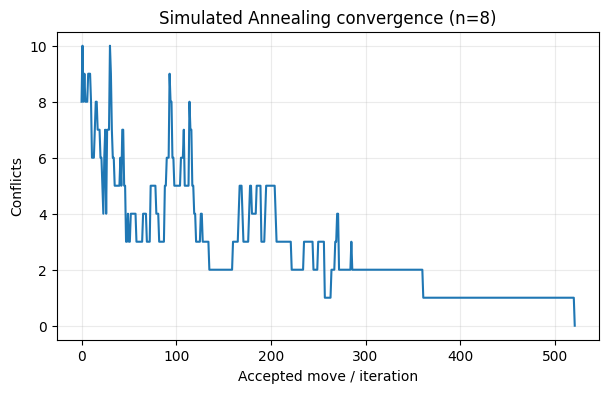

In [10]:
def simulated_annealing(board, T0=2.0, alpha=0.995, max_steps=20_000, schedule='exponential'):
    """Minimize conflicts; accept worsening moves with probability exp(-delta/T)."""
    import math
    board = np.array(board, dtype=int).copy(); n = len(board)
    current = conflicts(board); best_board = board.copy(); best = current
    history = [current]; evaluations = 1
    for t in range(1, max_steps+1):
        if best == 0: break
        col = np.random.randint(n); row = np.random.randint(n-1)
        if row >= board[col]: row += 1
        neighbor = board.copy(); neighbor[col] = row
        value = conflicts(neighbor); evaluations += 1
        if schedule == 'exponential': T = T0 * (alpha ** t)
        elif schedule == 'linear': T = max(1e-9, T0 - 0.0001*t)
        elif schedule == 'fast': T = T0/(1+t)
        elif schedule == 'logarithmic': T = T0/np.log1p(t)
        else: raise ValueError('Unknown schedule')
        delta = value-current
        if delta < 0 or (T > 0 and np.random.random() < math.exp(-delta/T)):
            board = neighbor; current = value
        if current < best:
            best = current; best_board = board.copy()
        history.append(current)
    return {"board": best_board, "conflicts": best, "steps": len(history)-1,
            "evaluations": evaluations, "history": history}

sa = simulated_annealing(random_board(8))
print({k:v for k,v in sa.items() if k not in ('board','history')})
plt.figure(figsize=(7,4)); plt.plot(sa['history']); plt.xlabel('Accepted move / iteration'); plt.ylabel('Conflicts'); plt.title('Simulated Annealing convergence (n=8)'); plt.grid(alpha=.25); plt.show()


## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

In [11]:
# Reproducible benchmark: 100 independent runs for each algorithm and n=4,8.
import time
algorithms = {
    'Steepest HC': steepest_hill_climbing,
    'Stochastic all moves': stochastic_hill_climbing_all,
    'Efficient stochastic': stochastic_hill_climbing,
    'Simulated annealing': simulated_annealing,
}
benchmark_rows = []
for n in (4, 8):
    for name, algorithm in algorithms.items():
        outcomes=[]; durations=[]; steps_list=[]
        for rep in range(100):
            board = random_board(n)
            start = time.perf_counter()
            if name == 'Simulated annealing': out = algorithm(board, T0=2.0, alpha=0.995, max_steps=5000)
            else: out = algorithm(board)
            durations.append((time.perf_counter()-start)*1000)
            outcomes.append(out['conflicts']); steps_list.append(out['steps'])
        benchmark_rows.append({'Algorithm':name,'n':n,'Avg runtime (ms)':np.mean(durations),
                               'Avg final conflicts':np.mean(outcomes),'Success (%)':100*np.mean(np.array(outcomes)==0),
                               'Avg steps':np.mean(steps_list)})
benchmark_df = pd.DataFrame(benchmark_rows)
display(benchmark_df.round(4))


,Algorithm,n,Avg runtime (ms),Avg final conflicts,Success (%),Avg steps
0,Steepest HC,4,0.1923,0.71,36.0,1.53
1,Stochastic all moves,4,0.2432,0.71,39.0,2.09
2,Efficient stochastic,4,2.9761,0.89,27.0,1.95
3,Simulated annealing,4,0.9213,0.00,100.0,72.06
4,Steepest HC,8,2.6256,1.21,13.0,3.29
5,Stochastic all moves,8,4.1400,1.21,20.0,4.93
6,Efficient stochastic,8,27.1791,1.35,13.0,5.12
7,Simulated annealing,8,22.6557,0.02,98.0,1099.79


### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

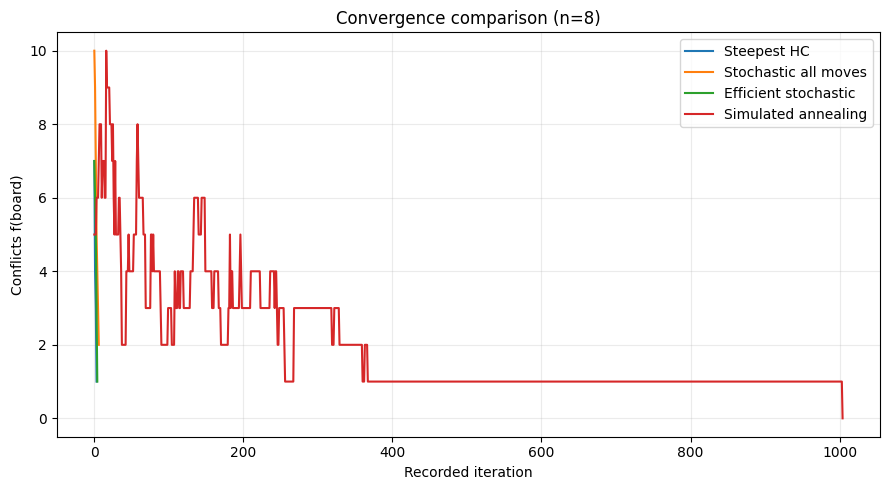

Steepest HC final= 1 evaluations= 225 steps= 3
Stochastic all moves final= 2 evaluations= 393 steps= 6
Efficient stochastic final= 1 evaluations= 678 steps= 4
Simulated annealing final= 0 evaluations= 1005 steps= 1004


In [12]:
# Representative convergence curves for n=8.
np.random.seed(2026)
representative = {
    'Steepest HC': steepest_hill_climbing(random_board(8)),
    'Stochastic all moves': stochastic_hill_climbing_all(random_board(8)),
    'Efficient stochastic': stochastic_hill_climbing(random_board(8)),
    'Simulated annealing': simulated_annealing(random_board(8), max_steps=5000),
}
plt.figure(figsize=(9,5))
for name, out in representative.items(): plt.plot(range(len(out['history'])), out['history'], label=name)
plt.xlabel('Recorded iteration'); plt.ylabel('Conflicts f(board)'); plt.title('Convergence comparison (n=8)')
plt.legend(); plt.grid(alpha=.25); plt.tight_layout(); plt.show()
for name,out in representative.items(): print(name, 'final=',out['conflicts'],'evaluations=',out['evaluations'],'steps=',out['steps'])


### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

Algorithm,Efficient stochastic,Steepest HC
n,,
4,2.7732,0.1808
8,25.2159,2.9667
12,100.8889,16.5854
16,206.0742,36.2047
20,422.6087,89.5757


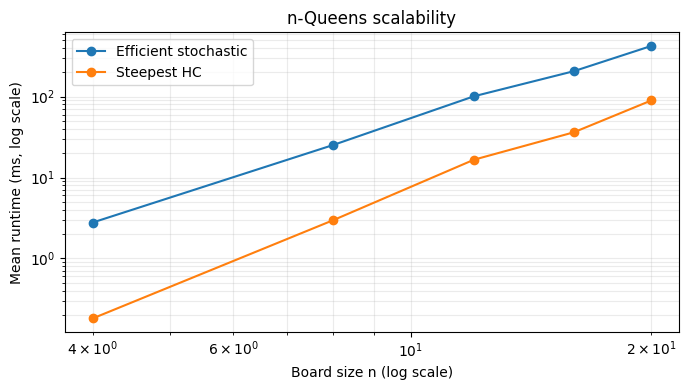

In [13]:
# Scalability experiment: use the efficient O(n) conflict counter in the search objective.
scalability_rows=[]
for n in (4,8,12,16,20):
    for name, algorithm in [('Steepest HC', steepest_hill_climbing), ('Efficient stochastic', stochastic_hill_climbing)]:
        times=[]
        reps=20
        for _ in range(reps):
            board=random_board(n); t0=time.perf_counter(); algorithm(board); times.append(time.perf_counter()-t0)
        scalability_rows.append({'Algorithm':name,'n':n,'Mean runtime (ms)':1000*np.mean(times)})
scalability_df=pd.DataFrame(scalability_rows)
display(scalability_df.pivot(index='n',columns='Algorithm',values='Mean runtime (ms)').round(4))
plt.figure(figsize=(7,4))
for name, group in scalability_df.groupby('Algorithm'):
    plt.loglog(group['n'],group['Mean runtime (ms)'],'o-',label=name)
plt.xlabel('Board size n (log scale)'); plt.ylabel('Mean runtime (ms, log scale)'); plt.title('n-Queens scalability')
plt.legend(); plt.grid(True,which='both',alpha=.25); plt.tight_layout(); plt.show()


## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

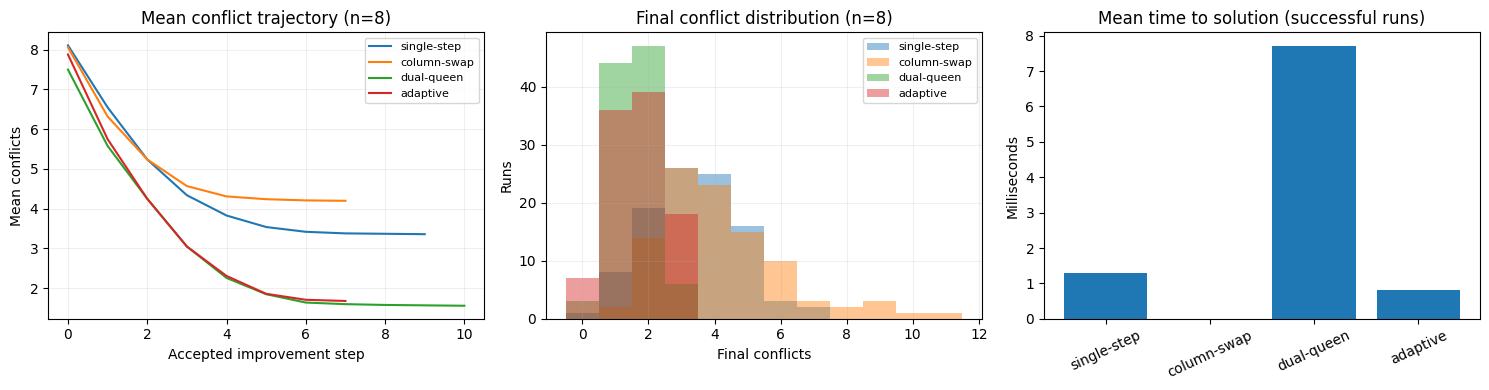

n=8:
  single-step: success=1.0%, mean final conflicts=3.360, mean runtime=8.044 ms, mean successful time=1.303 ms
  column-swap: success=0%, mean final conflicts=4.200, mean runtime=7.654 ms, no successful runs
  dual-queen: success=3.0%, mean final conflicts=1.560, mean runtime=9.083 ms, mean successful time=7.710 ms
  adaptive: success=7.0%, mean final conflicts=1.680, mean runtime=10.365 ms, mean successful time=0.819 ms


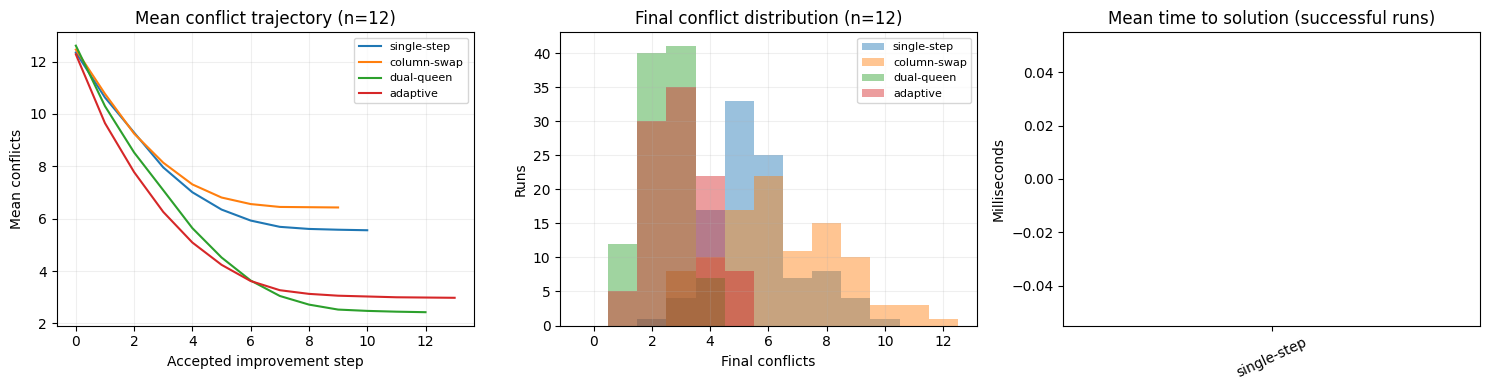

n=12:
  single-step: success=0%, mean final conflicts=5.560, mean runtime=13.106 ms, no successful runs
  column-swap: success=0%, mean final conflicts=6.430, mean runtime=12.402 ms, no successful runs
  dual-queen: success=0%, mean final conflicts=2.430, mean runtime=21.339 ms, no successful runs
  adaptive: success=0%, mean final conflicts=2.980, mean runtime=33.187 ms, no successful runs


In [14]:
# Advanced task: compare four move operators on n=8 and n=12 (100 runs each).
# This task is required for graduate students and optional bonus for undergraduates.
import time
from collections import defaultdict

def queen_conflicts_by_column(board):
    n = len(board)
    counts = np.zeros(n, dtype=int)
    for i in range(n):
        for j in range(n):
            if i != j and (board[i] == board[j] or abs(board[i]-board[j]) == abs(i-j)):
                counts[i] += 1
    return counts

def propose_neighbor(board, operator):
    n = len(board)
    candidate = np.array(board, dtype=int).copy()
    if operator == "single-step":
        col = np.random.randint(n)
        choices = [r for r in (candidate[col]-1, candidate[col]+1) if 0 <= r < n]
        if choices:
            candidate[col] = int(np.random.choice(choices))
    elif operator == "column-swap":
        i, j = np.random.choice(n, size=2, replace=False)
        candidate[i], candidate[j] = candidate[j], candidate[i]
    elif operator == "dual-queen":
        i, j = np.random.choice(n, size=2, replace=False)
        for col in (i, j):
            row = np.random.randint(n-1)
            if row >= candidate[col]:
                row += 1
            candidate[col] = row
    elif operator == "adaptive":
        # Focus the move on a queen involved in the largest number of conflicts.
        col = int(np.argmax(queen_conflicts_by_column(candidate)))
        row = np.random.randint(n-1)
        if row >= candidate[col]:
            row += 1
        candidate[col] = row
    else:
        raise ValueError("Unknown move operator")
    return candidate

def efficient_hc_with_operator(n, operator, max_trials_without_improvement=None, max_steps=5000):
    board = random_board(n)
    current = conflicts(board)
    history = [current]
    if max_trials_without_improvement is None:
        max_trials_without_improvement = 2*n*n
    stalled = 0
    for _ in range(max_steps):
        if current == 0:
            break
        neighbor = propose_neighbor(board, operator)
        value = conflicts(neighbor)
        if value < current:
            board, current = neighbor, value
            history.append(current)
            stalled = 0
        else:
            stalled += 1
        if stalled >= max_trials_without_improvement:
            break
    return {"conflicts": current, "history": history}

operators = ["single-step", "column-swap", "dual-queen", "adaptive"]
advanced_results = {}
for n in (8, 12):
    advanced_results[n] = {}
    for operator in operators:
        histories, final_values, successful_times = [], [], []
        all_times = []
        for _ in range(100):
            start = time.perf_counter()
            result = efficient_hc_with_operator(n, operator)
            elapsed = time.perf_counter() - start
            histories.append(result["history"])
            final_values.append(result["conflicts"])
            all_times.append(elapsed)
            if result["conflicts"] == 0:
                successful_times.append(elapsed)
        advanced_results[n][operator] = {
            "histories": histories,
            "final": final_values,
            "mean_time": float(np.mean(all_times)),
            "success_time": float(np.mean(successful_times)) if successful_times else float("nan"),
            "success_rate": float(np.mean(np.array(final_values) == 0) * 100),
        }

    # Align variable-length histories by carrying forward each run's last observed value.
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for operator in operators:
        runs = advanced_results[n][operator]["histories"]
        max_len = max(map(len, runs))
        aligned = np.array([h + [h[-1]]*(max_len-len(h)) for h in runs], dtype=float)
        axes[0].plot(np.mean(aligned, axis=0), label=operator)
        axes[1].hist(advanced_results[n][operator]["final"], bins=np.arange(-0.5, max(advanced_results[n][operator]["final"])+1.5, 1),
                     alpha=0.45, label=operator)
    axes[0].set_title(f"Mean conflict trajectory (n={n})")
    axes[0].set_xlabel("Accepted improvement step"); axes[0].set_ylabel("Mean conflicts")
    axes[0].legend(fontsize=8); axes[0].grid(alpha=0.2)
    axes[1].set_title(f"Final conflict distribution (n={n})")
    axes[1].set_xlabel("Final conflicts"); axes[1].set_ylabel("Runs")
    axes[1].legend(fontsize=8); axes[1].grid(alpha=0.2)
    success_means = [advanced_results[n][op]["success_time"]*1000 for op in operators]
    axes[2].bar(operators, success_means)
    axes[2].set_title("Mean time to solution (successful runs)")
    axes[2].set_ylabel("Milliseconds"); axes[2].tick_params(axis="x", rotation=25)
    plt.tight_layout(); plt.show()

    print(f"n={n}:")
    for operator in operators:
        r = advanced_results[n][operator]
        print(f"  {operator}: success={r['success_rate']:.1f}%, mean final conflicts={np.mean(r['final']):.3f}, "
              f"mean runtime={r['mean_time']*1000:.3f} ms, mean successful time="
              f"{r['success_time']*1000:.3f} ms" if not np.isnan(r['success_time']) else
              f"  {operator}: success=0%, mean final conflicts={np.mean(r['final']):.3f}, mean runtime={r['mean_time']*1000:.3f} ms, no successful runs")


## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [15]:
# Optional bonus: Genetic Algorithm. This is outside the required core deliverables and is not used in the report.